# Color-Invariant Saree Design Recognition

## Project Objective

The objective of this project is to develop a deep-learning based saree-pattern retrieval system that can identify visually similar saree designs while being robust to changes in color and appearance.

The system learns compact image embeddings and uses similarity-based retrieval to rank gallery images for a given query image.

## 1. Approach

A pretrained ResNet-18 is used as the backbone and converted into a 128-dimensional L2-normalized embedding model for saree-pattern retrieval. Each training image generates two augmented views using random resized cropping, horizontal flipping, and strong ColorJitter to encourage color invariance.

The model is trained using NT-Xent contrastive loss with a temperature of 0.2. AdamW optimization is used with a learning rate of 1e-4 and weight decay of 1e-4. The batch size is 32 and training is performed for 5 epochs. Other images in the batch provide negative examples.

## 2. Dataset and Preprocessing

Two datasets specified in the assignment were inspected:

- **Indian Saree Patterns:** 1,468 images covering four pattern categories: Banarasi, Bandhani, Ikat, and Pichwai.
- **DeepLure Handloom Saree subset:** 165 images were inspected.

The Indian Saree Patterns dataset was used for model training and evaluation because it provided clear category labels. Images were converted to RGB and processed using a ResNet-18 compatible 224 × 224 input size.

During training, RandomResizedCrop, RandomHorizontalFlip, and ColorJitter were applied. ColorJitter was intentionally used with strong brightness, contrast, saturation, and hue changes to encourage the learned representation to focus on pattern structure rather than color.

## 3. Dataset Split

The Indian Saree Patterns dataset was used for training and evaluation with its provided train, validation, and test organization.

The training set contains 1,293 images, the validation set contains 115 images, and the test set contains 60 images across four categories: Banarasi, Bandhani, Ikat, and Pichwai.

For the final retrieval evaluation, the 60 test images were further divided into a disjoint gallery and query set. The gallery contains 29 images and the query set contains 31 images. No query image was included in the gallery.

This disjoint split was used as the primary retrieval evaluation because it prevents the exact query image from appearing in the gallery.

## 4. Model Architecture

A pretrained ResNet-18 convolutional neural network is used as the visual backbone.

The original classification layer was replaced with a projection head:

ResNet-18 features → Linear(512, 256) → ReLU → Linear(256, 128)

The resulting 128-dimensional representation is L2-normalized before similarity computation.

Cosine similarity between normalized embeddings is used to rank gallery images for a query image.

The model contains 11,340,736 total trainable parameters and produces compact 128-dimensional embeddings.

## 5. Training Strategy

The model is trained using self-supervised contrastive learning.

For every training image, two independently augmented views are generated. These two views form a positive pair because they originate from the same image. Other views within the mini-batch act as negative examples.

NT-Xent contrastive loss is used with a temperature of 0.2.

Training configuration:

- Optimizer: AdamW
- Learning rate: 1e-4
- Weight decay: 1e-4
- Batch size: 32
- Training epochs: 5
- Embedding dimension: 128

Strong ColorJitter augmentation is used to encourage the representation to focus on saree pattern structure rather than relying heavily on color.

## 6. Evaluation Protocol

Two evaluation settings were used.

### Controlled Color-Invariance Evaluation

Each test image was used as a query after applying a controlled color transformation, while the original image remained in the gallery. This evaluates whether the learned representation remains stable under changes in brightness, contrast, saturation, and hue.

Identification was evaluated using Top-1, Top-5, and Top-10 retrieval accuracy.

Verification was evaluated by comparing positive query-gallery similarity against the hardest negative similarity and selecting the threshold that produced the highest verification accuracy on the controlled test pairs.

### Disjoint Gallery/Query Evaluation

For a more realistic retrieval evaluation, the test images were divided into a gallery of 29 images and a query set of 31 images. No query image was present in the gallery.

The predicted category was determined from the highest-similarity retrieved gallery image. Top-1, Top-5, and Top-10 retrieval accuracy were calculated, along with a confusion matrix and per-category precision, recall, and F1-score.

The disjoint evaluation is treated as the primary retrieval result.

In [117]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
else:
    print("GPU is NOT available")

PyTorch version: 2.11.0+cu128
GPU available: True
GPU name: Tesla T4
Number of GPUs: 2


In [118]:

DATASET_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns"
print("Dataset contents:\n")

for item in os.listdir(DATASET_PATH):
    print(item)

Dataset contents:

README.dataset.txt
README.roboflow.txt
valid
test
train


In [119]:

TRAIN_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns/train"
print("Contents of train:\n")

for item in os.listdir(TRAIN_PATH):
    print(item)

VALID_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns/valid"

print("Contents of valid:\n")

for item in os.listdir(VALID_PATH):
    print(item)

TEST_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns/test"

print("Contents of test:\n")

for item in os.listdir(TEST_PATH):
    print(item)

Contents of train:

Banarasi
Pichwai
Bandhani
Ikat
Contents of valid:

Banarasi
Pichwai
Bandhani
Ikat
Contents of test:

Banarasi
Pichwai
Bandhani
Ikat


In [120]:
BASE_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns"

splits = ["train", "valid", "test"]
categories = ["Banarasi", "Pichwai", "Bandhani", "Ikat"]

for split in splits:
    print(f"\n--- {split.upper()} ---")

    for category in categories:
        folder = os.path.join(BASE_PATH, split, category)

        files = [
            f for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
        ]

        print(f"{category}: {len(files)} files")


--- TRAIN ---
Banarasi: 432 files
Pichwai: 279 files
Bandhani: 279 files
Ikat: 303 files

--- VALID ---
Banarasi: 43 files
Pichwai: 24 files
Bandhani: 22 files
Ikat: 26 files

--- TEST ---
Banarasi: 14 files
Pichwai: 18 files
Bandhani: 15 files
Ikat: 13 files


In [121]:
from PIL import Image
import matplotlib.pyplot as plt

BASE_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns"

categories = ["Banarasi", "Pichwai", "Bandhani", "Ikat"]

for category in categories:
    folder = os.path.join(BASE_PATH, "train", category)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print(category, "→", image_files[:3])

Banarasi → ['images46_jpg.rf.062e7b01baadf52ffd6e44a138d7b454.jpg', 'sfj48245_jpg.rf.39a3025f98f27cfb03da805dd85f1bbb.jpg', 'images176_jpg.rf.e0af7ada0ff4824674050c51e5d1df99.jpg']
Pichwai → ['pastel-hand-painted-pure-moonga-silk-pichwai-blouse-fabric-1-mtr-775928_jpg.rf.3f897b4efc4aac8fc8aa5872826cd01c.jpg', 'WhatsAppImage2024-04-12at4-09-20PM_jpg.rf.5ca351c9844802e891b01cfa40787534.jpg', 'WhatsAppImage2022-07-29at11-41-25AM_2_jpg.rf.9fca7409ff4ba96a27c8f0fa5f5eaab0.jpg']
Bandhani → ['images4_jpg.rf.ebd63c7c701d943d15cc996137fa0a1c.jpg', 'images_jpg.rf.24e1bb0bca640f83ab02dcc8fbd40a07.jpg', 'image26_jpeg.rf.1e5d325521d8107e12e38276ca467645.jpg']
Ikat → ['51033030-e5ae-4c6d-8aa8-9625fde8ce96_jpg.rf.340898ed5b6fccc4f460307f0dd692a1.jpg', 'images29_jpg.rf.a185c7591152a70de334deaea48d4b14.jpg', '79_jpg.rf.2b6c03a243fa81115c03ad87cf445dc8.jpg']


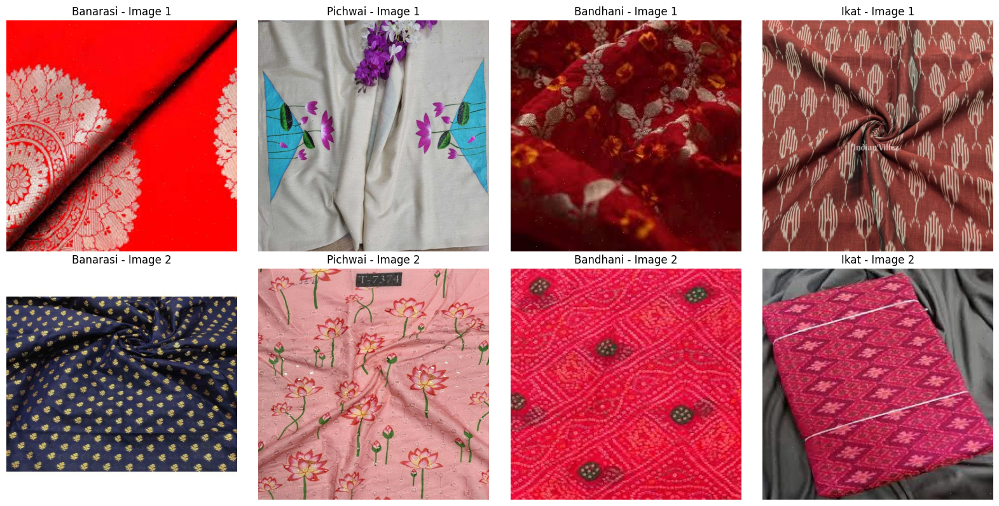

In [122]:
from PIL import Image
import matplotlib.pyplot as plt
import os

BASE_PATH = "/kaggle/input/datasets/div456/indian-saree-patterns"

categories = ["Banarasi", "Pichwai", "Bandhani", "Ikat"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, category in enumerate(categories):
    folder = os.path.join(BASE_PATH, "train", category)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    for j in range(2):
        image_path = os.path.join(folder, image_files[j])
        image = Image.open(image_path)

        axes[j, i].imshow(image)
        axes[j, i].set_title(f"{category} - Image {j+1}")
        axes[j, i].axis("off")

plt.tight_layout()
plt.show()

In [123]:
for fname in ["README.dataset.txt", "README.roboflow.txt"]:
    path = os.path.join(BASE_PATH, fname)

    print("\n" + "=" * 70)
    print(fname)
    print("=" * 70)

    with open(path, "r", errors="ignore") as f:
        print(f.read()[:10000])


README.dataset.txt
# Indian Fabric Patterns > 2024-05-26 3:25pm
https://universe.roboflow.com/div-szivu/indian-fabric-patterns

Provided by a Roboflow user
License: MIT



README.roboflow.txt

Indian Fabric Patterns - v1 2024-05-26 3:25pm

This dataset was exported via roboflow.com on May 26, 2024 at 10:01 AM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 1468 images.
Ikat-Banarasi-Bandhani-Pichwai are annotated in folder format.

The following pre-pr

In [124]:
from PIL import Image
import os

image_info = []

for category in categories:
    folder = os.path.join(BASE_PATH, "train", category)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            path = os.path.join(folder, filename)

            with Image.open(path) as img:
                image_info.append({
                    "category": category,
                    "filename": filename,
                    "size": img.size,
                    "mode": img.mode,
                    "format": img.format
                })

            if len(image_info) >= 20:
                break

    if len(image_info) >= 20:
        break

print("Number of images checked:", len(image_info))

for item in image_info[:10]:
    print(item)

Number of images checked: 20
{'category': 'Banarasi', 'filename': 'images46_jpg.rf.062e7b01baadf52ffd6e44a138d7b454.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'sfj48245_jpg.rf.39a3025f98f27cfb03da805dd85f1bbb.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'images176_jpg.rf.e0af7ada0ff4824674050c51e5d1df99.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'images174_jpg.rf.eae3d1623354c6103d86d6a4116a91bb.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'images58_jpg.rf.22eebdc8a76412c7eaa6f1aeaa64b41a.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'images32_jpg.rf.eb22f1ba833ebfed60e38b596e8bea19.jpg', 'size': (640, 640), 'mode': 'RGB', 'format': 'JPEG'}
{'category': 'Banarasi', 'filename': 'images107_jpg.rf.40283f4b5da6424dea3ba0923362b121.jpg',

In [125]:
for category in categories:
    folder = os.path.join(BASE_PATH, "train", category)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print(f"\n{category}: {len(files)} images")
    print("First 5 filenames:")

    for f in files[:5]:
        print("  ", f)


Banarasi: 432 images
First 5 filenames:
   images46_jpg.rf.062e7b01baadf52ffd6e44a138d7b454.jpg
   sfj48245_jpg.rf.39a3025f98f27cfb03da805dd85f1bbb.jpg
   images176_jpg.rf.e0af7ada0ff4824674050c51e5d1df99.jpg
   images174_jpg.rf.eae3d1623354c6103d86d6a4116a91bb.jpg
   images58_jpg.rf.22eebdc8a76412c7eaa6f1aeaa64b41a.jpg

Pichwai: 279 images
First 5 filenames:
   pastel-hand-painted-pure-moonga-silk-pichwai-blouse-fabric-1-mtr-775928_jpg.rf.3f897b4efc4aac8fc8aa5872826cd01c.jpg
   WhatsAppImage2024-04-12at4-09-20PM_jpg.rf.5ca351c9844802e891b01cfa40787534.jpg
   WhatsAppImage2022-07-29at11-41-25AM_2_jpg.rf.9fca7409ff4ba96a27c8f0fa5f5eaab0.jpg
   images12_jpg.rf.35bbd7477776b0f6c3fe8bc090ce7fd8.jpg
   PICHWAI-100009-03_jpg.rf.1414dec2c83cad530a1cdca9a6026c7e.jpg

Bandhani: 279 images
First 5 filenames:
   images4_jpg.rf.ebd63c7c701d943d15cc996137fa0a1c.jpg
   images_jpg.rf.24e1bb0bca640f83ab02dcc8fbd40a07.jpg
   image26_jpeg.rf.1e5d325521d8107e12e38276ca467645.jpg
   image24_jpeg.rf.7c964

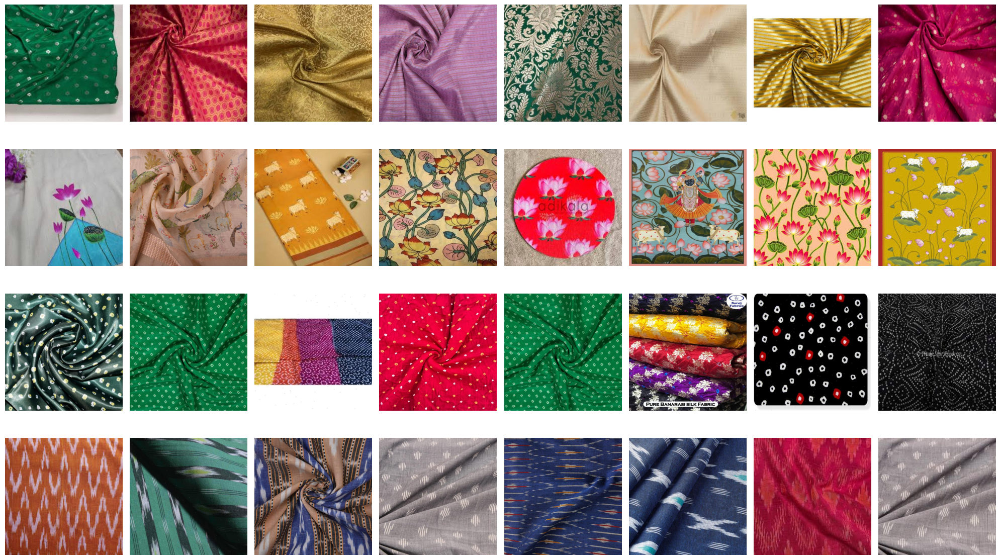

In [126]:
import random
fig, axes = plt.subplots(4, 8, figsize=(20, 12))

for row, category in enumerate(categories):
    folder = os.path.join(BASE_PATH, "train", category)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    sample_files = random.sample(files, min(8, len(files)))

    for col, filename in enumerate(sample_files):
        image_path = os.path.join(folder, filename)
        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                category,
                fontsize=12,
                fontweight="bold"
            )

plt.tight_layout()
plt.show()

In [127]:
import hashlib

def get_file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


hashes = {}

for split in ["train", "valid", "test"]:
    for category in categories:

        folder = os.path.join(BASE_PATH, split, category)

        for filename in os.listdir(folder):

            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):

                path = os.path.join(folder, filename)
                file_hash = get_file_hash(path)

                if file_hash not in hashes:
                    hashes[file_hash] = []

                hashes[file_hash].append(
                    (split, category, filename)
                )


duplicate_groups = [
    items for items in hashes.values()
    if len(items) > 1
]

print("Total unique image files:", len(hashes))
print("Duplicate groups:", len(duplicate_groups))

for i, group in enumerate(duplicate_groups[:10]):
    print(f"\nDuplicate group {i + 1}:")
    for item in group:
        print("  ", item)

Total unique image files: 1463
Duplicate groups: 5

Duplicate group 1:
   ('train', 'Pichwai', 'fab-14050_800x_jpg.rf.804e68a7cceccad74c6f0d61f82eb516.jpg')
   ('train', 'Pichwai', 'fab-14050_800x_jpg.rf.b7a1c91973f41ebc94a1d2f8d6a6798e.jpg')

Duplicate group 2:
   ('train', 'Pichwai', 'Instagrampost-251_800x_png.rf.9a9325ebcb2dd24bc837901c647108ab.jpg')
   ('train', 'Pichwai', 'Instagrampost-251_800x_png.rf.07dba6d6ab9c7b805e4a4fa7e8586490.jpg')

Duplicate group 3:
   ('train', 'Bandhani', '20210407_103036-480x480_jpg.rf.0edc4da9daa1694820add04d2e201a8c.jpg')
   ('train', 'Bandhani', '20210407_103036-480x480_jpg.rf.92f83d9aaf59296fb89fe59689a46491.jpg')

Duplicate group 4:
   ('train', 'Bandhani', 'image31_jpeg.rf.4b66acafcab415052bf7c3606ee45982.jpg')
   ('train', 'Bandhani', 'image31_jpeg.rf.e4507719b75e91abc905d77fa95a28ae.jpg')

Duplicate group 5:
   ('train', 'Ikat', 'f23-3_28011e9d-4d11-40a8-8ead-d1570fd16907_1200x_jpg.rf.6050478d7b0904ac25be3ba6ed3166f7.jpg')
   ('train', 'Ikat

In [128]:
for i, group in enumerate(duplicate_groups):

    print(f"\nDuplicate Group {i + 1}")

    splits = set()

    for split, category, filename in group:
        print(f"  {split:5} | {category:10} | {filename}")
        splits.add(split)

    if len(splits) > 1:
        print("  ⚠️ CROSS-SPLIT DUPLICATE")
    else:
        print("  ✓ Same split only")


Duplicate Group 1
  train | Pichwai    | fab-14050_800x_jpg.rf.804e68a7cceccad74c6f0d61f82eb516.jpg
  train | Pichwai    | fab-14050_800x_jpg.rf.b7a1c91973f41ebc94a1d2f8d6a6798e.jpg
  ✓ Same split only

Duplicate Group 2
  train | Pichwai    | Instagrampost-251_800x_png.rf.9a9325ebcb2dd24bc837901c647108ab.jpg
  train | Pichwai    | Instagrampost-251_800x_png.rf.07dba6d6ab9c7b805e4a4fa7e8586490.jpg
  ✓ Same split only

Duplicate Group 3
  train | Bandhani   | 20210407_103036-480x480_jpg.rf.0edc4da9daa1694820add04d2e201a8c.jpg
  train | Bandhani   | 20210407_103036-480x480_jpg.rf.92f83d9aaf59296fb89fe59689a46491.jpg
  ✓ Same split only

Duplicate Group 4
  train | Bandhani   | image31_jpeg.rf.4b66acafcab415052bf7c3606ee45982.jpg
  train | Bandhani   | image31_jpeg.rf.e4507719b75e91abc905d77fa95a28ae.jpg
  ✓ Same split only

Duplicate Group 5
  train | Ikat       | f23-3_28011e9d-4d11-40a8-8ead-d1570fd16907_1200x_jpg.rf.6050478d7b0904ac25be3ba6ed3166f7.jpg
  train | Ikat       | f23-3_28

In [129]:
for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/div456
/kaggle/input/datasets/div456/indian-saree-patterns
/kaggle/input/datasets/div456/indian-saree-patterns/valid
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Pichwai
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Bandhani
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Ikat
/kaggle/input/datasets/div456/indian-saree-patterns/test
/kaggle/input/datasets/div456/indian-saree-patterns/test/Banarasi
/kaggle/input/datasets/div456/indian-saree-patterns/test/Pichwai
/kaggle/input/datasets/div456/indian-saree-patterns/test/Bandhani
/kaggle/input/datasets/div456/indian-saree-patterns/test/Ikat
/kaggle/input/datasets/div456/indian-saree-patterns/train
/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi
/kaggle/input/datasets/div456/indian-saree-patterns/train/Pichwai
/kaggle/input/datasets/div456/indian-saree-patterns/t

In [130]:
handloom_path = "/kaggle/input/datasets/akashchakali18/handloom-saree1/handloom_sarees"

print("Number of images:", len(os.listdir(handloom_path)))
print("First 5 files:")

for file in os.listdir(handloom_path)[:5]:
    print(file)

Number of images: 165
First 5 files:
img_568910.jpg
img_586537.jpg
img_357974.jpg
img_354459.jpg
img_804542.jpg


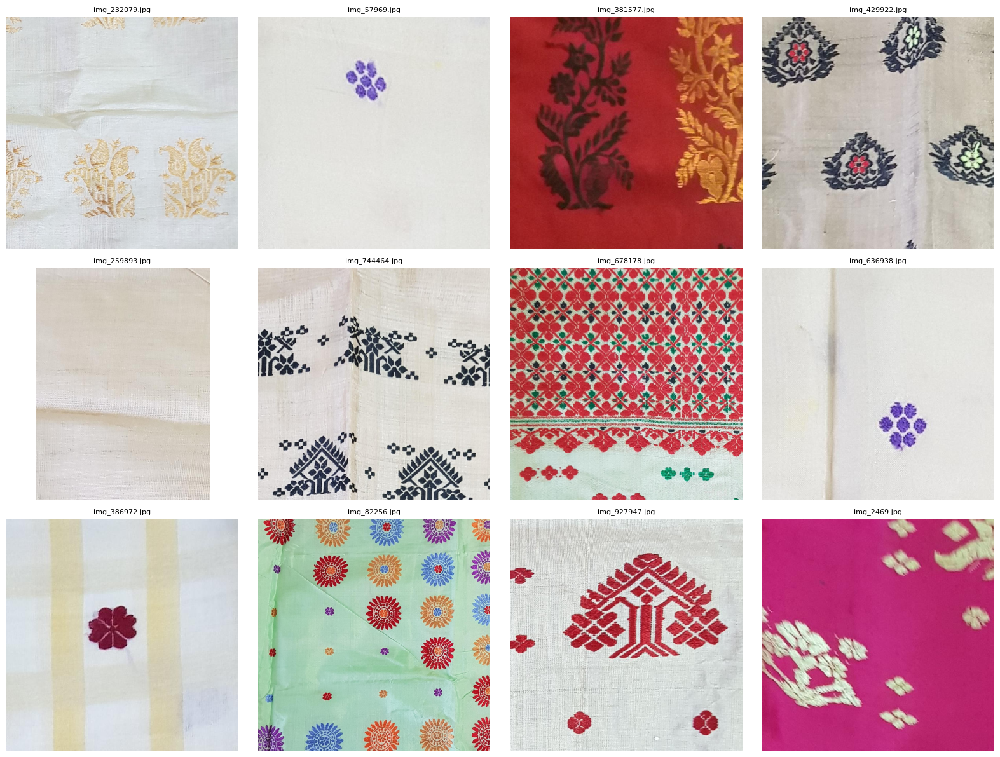

In [131]:
sample_files = random.sample(os.listdir(handloom_path), 12)

plt.figure(figsize=(16, 12))

for i, file in enumerate(sample_files):
    img = Image.open(os.path.join(handloom_path, file))

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(file[:18], fontsize=8)

plt.tight_layout()
plt.show()

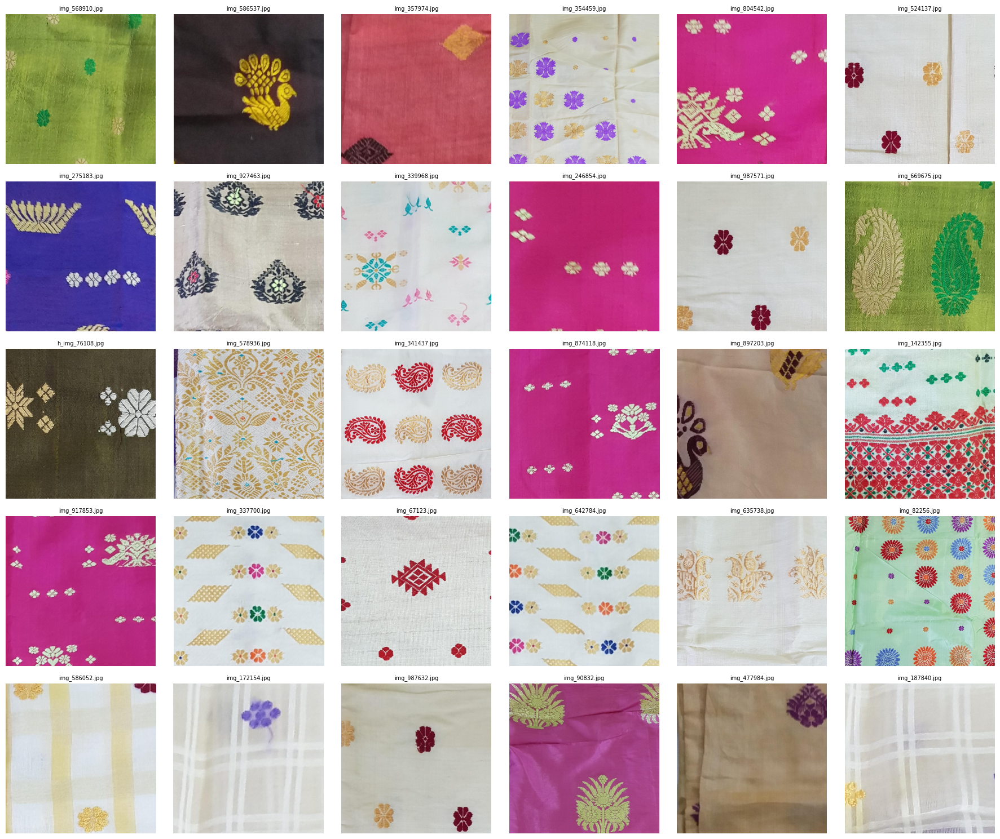

Showing images 1 to 30


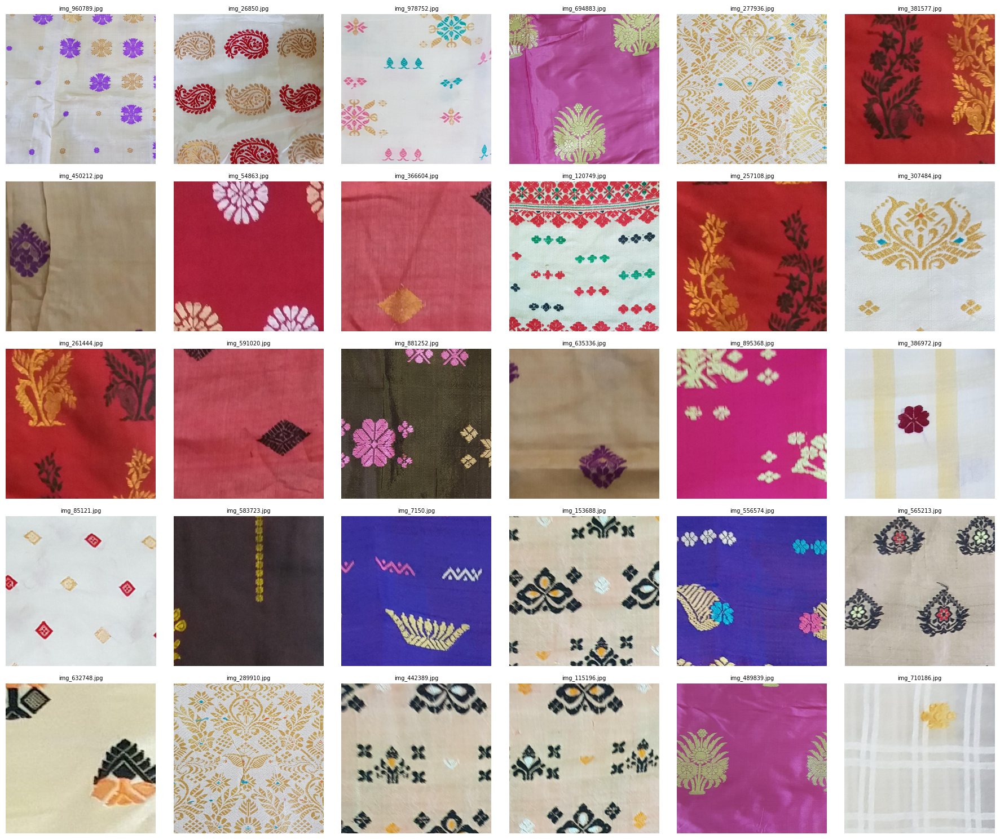

Showing images 31 to 60


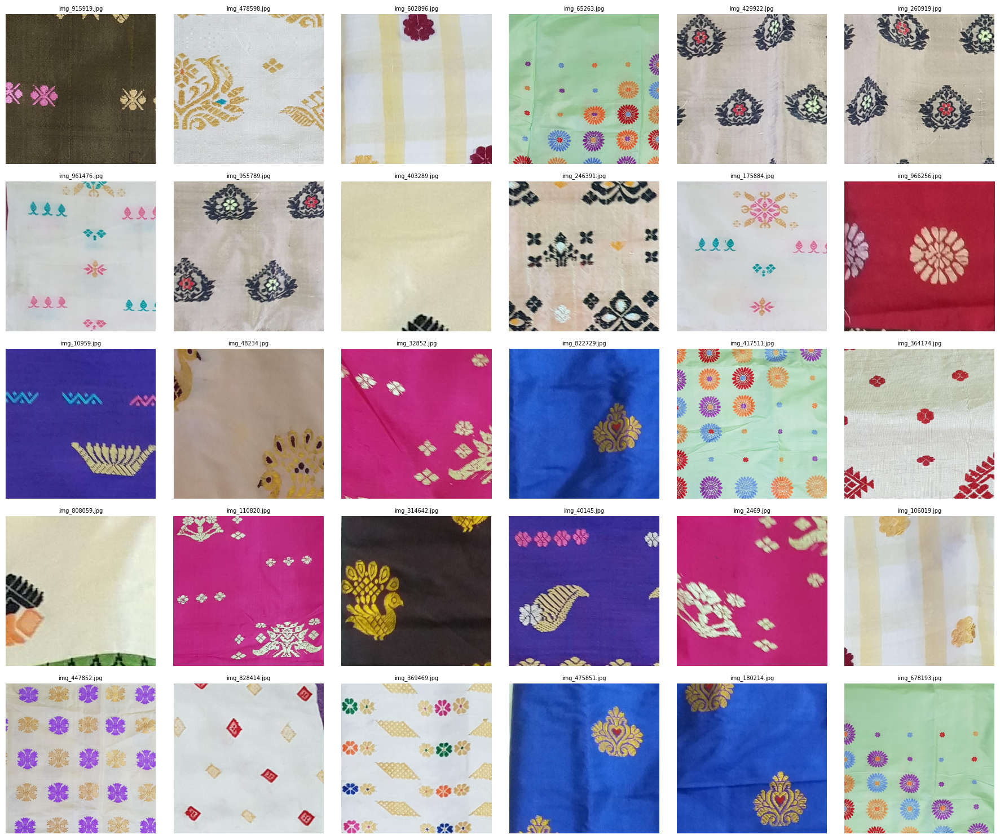

Showing images 61 to 90


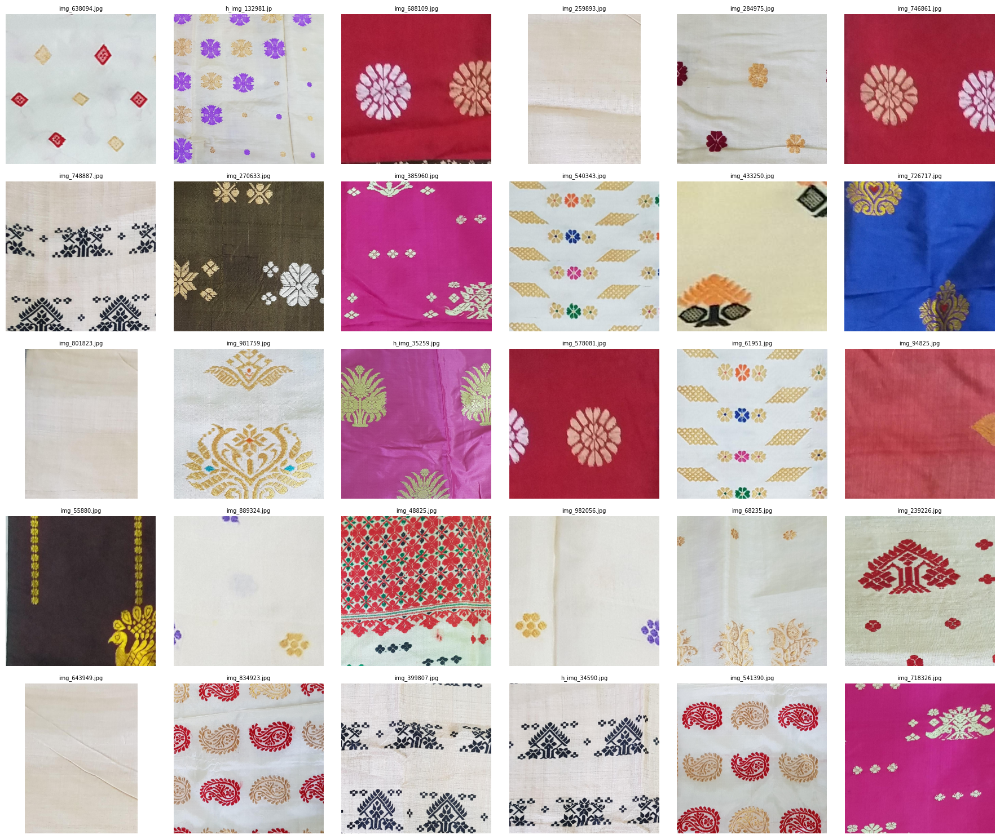

Showing images 91 to 120


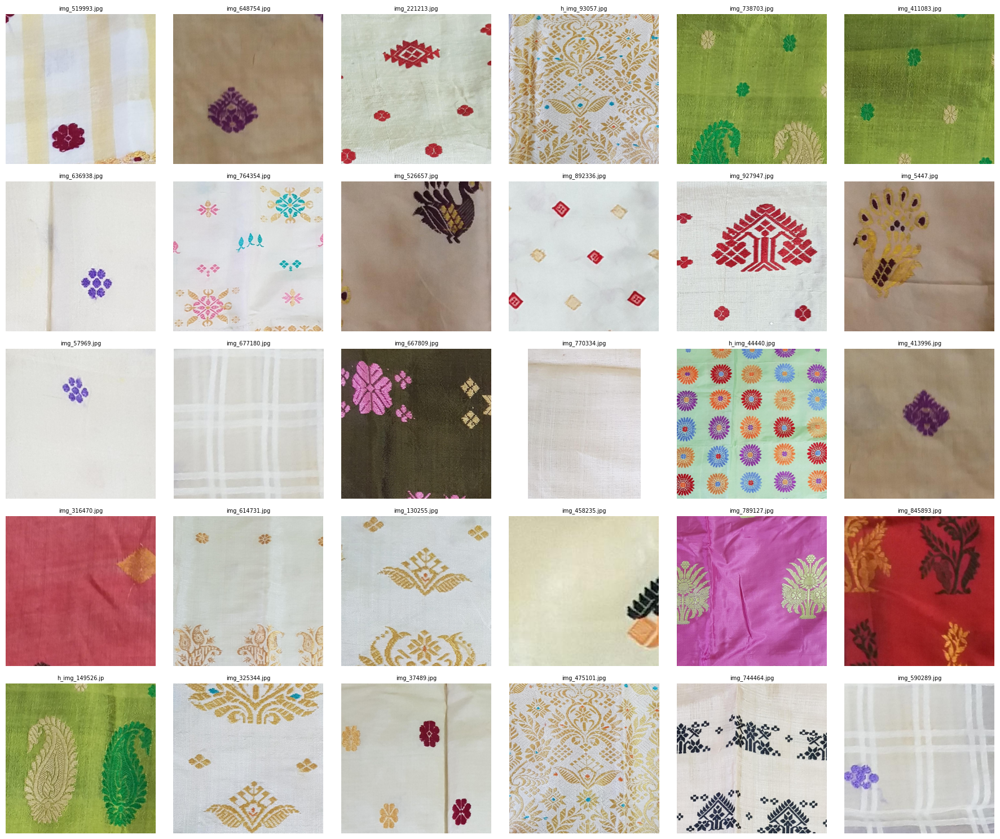

Showing images 121 to 150


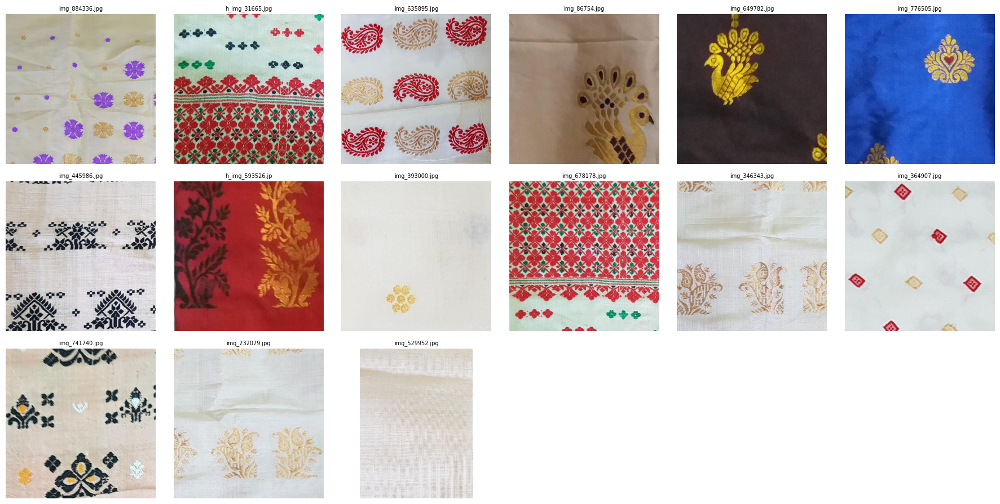

Showing images 151 to 165


In [132]:
all_files = os.listdir(handloom_path)

for start in range(0, len(all_files), 30):
    batch = all_files[start:start + 30]

    plt.figure(figsize=(18, 15))

    for i, file in enumerate(batch):
        img = Image.open(os.path.join(handloom_path, file))

        plt.subplot(5, 6, i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(file[:15], fontsize=7)

    plt.tight_layout()
    plt.show()

    print(f"Showing images {start + 1} to {start + len(batch)}")

In [133]:
image_sizes = {}

for file in os.listdir(handloom_path):
    try:
        img = Image.open(os.path.join(handloom_path, file))
        image_sizes[img.size] = image_sizes.get(img.size, 0) + 1
    except:
        pass

print("Number of different image sizes:", len(image_sizes))
print("\nImage sizes:")
for size, count in image_sizes.items():
    print(size, ":", count)

Number of different image sizes: 78

Image sizes:
(730, 730) : 5
(629, 629) : 4
(662, 662) : 5
(1511, 1512) : 6
(641, 641) : 6
(919, 919) : 4
(485, 485) : 2
(985, 986) : 1
(641, 642) : 1
(918, 918) : 1
(875, 874) : 1
(1286, 1286) : 2
(1376, 1376) : 2
(708, 707) : 3
(553, 553) : 4
(708, 708) : 2
(656, 655) : 3
(908, 907) : 3
(656, 656) : 2
(1085, 1085) : 2
(1368, 1367) : 2
(590, 589) : 4
(471, 470) : 2
(1260, 1260) : 1
(598, 598) : 5
(471, 471) : 2
(1512, 1512) : 4
(1375, 1376) : 3
(985, 985) : 2
(1259, 1260) : 1
(1285, 1286) : 3
(610, 610) : 5
(493, 494) : 1
(893, 893) : 4
(874, 875) : 1
(589, 590) : 2
(485, 486) : 1
(631, 631) : 2
(227, 227) : 4
(632, 632) : 1
(631, 632) : 1
(1260, 1259) : 1
(875, 875) : 2
(894, 894) : 1
(642, 642) : 1
(986, 986) : 1
(226, 226) : 1
(632, 631) : 1
(986, 985) : 1
(494, 493) : 2
(486, 486) : 1
(642, 641) : 2
(581, 581) : 2
(1367, 1367) : 2
(486, 485) : 1
(589, 589) : 4
(582, 582) : 1
(493, 493) : 2
(664, 885) : 3
(1186, 1186) : 1
(582, 581) : 1
(664, 886

In [134]:
import numpy as np
from PIL import ImageOps

In [135]:
from PIL import ImageFilter

# Store grayscale pattern representations
pattern_features = {}
valid_files = []

for file in os.listdir(handloom_path):
    file_path = os.path.join(handloom_path, file)

    try:
        img = Image.open(file_path).convert("L")

        # Standardize temporarily for comparison
        img = img.resize((64, 64))

        # Emphasize edges/patterns rather than color
        img = img.filter(ImageFilter.FIND_EDGES)

        arr = np.array(img, dtype=np.float32)

        # Normalize
        arr = arr - arr.mean()
        norm = np.linalg.norm(arr)

        if norm > 0:
            arr = arr / norm

        pattern_features[file] = arr.flatten()
        valid_files.append(file)

    except Exception as e:
        print("Skipped:", file, e)

print("Images successfully processed:", len(valid_files))

Images successfully processed: 165


In [136]:
similar_pairs = []

for i in range(len(valid_files)):
    for j in range(i + 1, len(valid_files)):

        f1 = valid_files[i]
        f2 = valid_files[j]

        similarity = np.dot(
            pattern_features[f1],
            pattern_features[f2]
        )

        similar_pairs.append((similarity, f1, f2))

# Highest similarity first
similar_pairs.sort(reverse=True)

print("Total pairs compared:", len(similar_pairs))
print("\nTop 20 most similar pairs:\n")

for score, f1, f2 in similar_pairs[:20]:
    print(f"{score:.4f}  |  {f1}  <-->  {f2}")

Total pairs compared: 13530

Top 20 most similar pairs:

0.9767  |  img_801823.jpg  <-->  img_529952.jpg
0.9761  |  img_259893.jpg  <-->  img_801823.jpg
0.9757  |  img_259893.jpg  <-->  img_643949.jpg
0.9754  |  img_259893.jpg  <-->  img_529952.jpg
0.9751  |  img_801823.jpg  <-->  img_643949.jpg
0.9745  |  img_259893.jpg  <-->  img_393000.jpg
0.9743  |  img_393000.jpg  <-->  img_529952.jpg
0.9743  |  img_643949.jpg  <-->  img_529952.jpg
0.9737  |  img_801823.jpg  <-->  img_770334.jpg
0.9737  |  img_801823.jpg  <-->  img_393000.jpg
0.9732  |  img_770334.jpg  <-->  img_529952.jpg
0.9723  |  img_643949.jpg  <-->  img_393000.jpg
0.9709  |  img_259893.jpg  <-->  img_770334.jpg
0.9697  |  img_643949.jpg  <-->  img_770334.jpg
0.9688  |  img_770334.jpg  <-->  img_393000.jpg
0.9636  |  img_677180.jpg  <-->  img_529952.jpg
0.9620  |  img_801823.jpg  <-->  img_677180.jpg
0.9619  |  img_643949.jpg  <-->  img_677180.jpg
0.9617  |  img_259893.jpg  <-->  img_677180.jpg
0.9599  |  img_677180.jpg  <-->

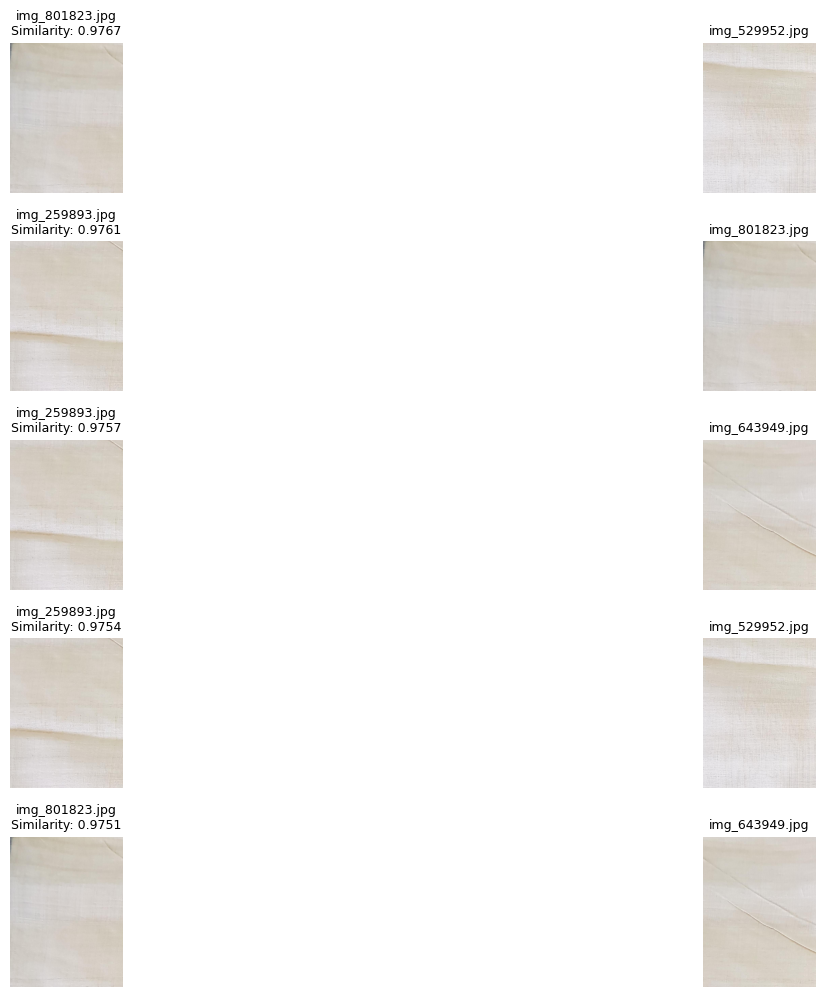

In [137]:
top_pairs = similar_pairs[:5]

plt.figure(figsize=(14, 20))

for i, (score, f1, f2) in enumerate(top_pairs):
    img1 = Image.open(os.path.join(handloom_path, f1))
    img2 = Image.open(os.path.join(handloom_path, f2))

    # First image
    plt.subplot(10, 2, 2 * i + 1)
    plt.imshow(img1)
    plt.axis("off")
    plt.title(f"{f1}\nSimilarity: {score:.4f}", fontsize=9)

    # Second image
    plt.subplot(10, 2, 2 * i + 2)
    plt.imshow(img2)
    plt.axis("off")
    plt.title(f"{f2}", fontsize=9)

plt.tight_layout()
plt.show()

In [138]:
indian_path = "/kaggle/input/datasets/div456/indian-saree-patterns"

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    split_path = os.path.join(indian_path, split)

    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)
        count = len(os.listdir(class_path))
        print(f"{class_name}: {count}")


TRAIN
Banarasi: 432
Pichwai: 279
Bandhani: 279
Ikat: 303

VALID
Banarasi: 43
Pichwai: 24
Bandhani: 22
Ikat: 26

TEST
Banarasi: 14
Pichwai: 18
Bandhani: 15
Ikat: 13


In [139]:
train_path = os.path.join(indian_path, "train")

train_files = []

for class_name in os.listdir(train_path):
    class_path = os.path.join(train_path, class_name)

    for file in os.listdir(class_path):
        file_path = os.path.join(class_path, file)

        if os.path.isfile(file_path):
            train_files.append({
                "path": file_path,
                "class": class_name
            })

print("Total training images:", len(train_files))
print("\nFirst 5:")
for item in train_files[:5]:
    print(item)

Total training images: 1293

First 5:
{'path': '/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi/images46_jpg.rf.062e7b01baadf52ffd6e44a138d7b454.jpg', 'class': 'Banarasi'}
{'path': '/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi/sfj48245_jpg.rf.39a3025f98f27cfb03da805dd85f1bbb.jpg', 'class': 'Banarasi'}
{'path': '/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi/images176_jpg.rf.e0af7ada0ff4824674050c51e5d1df99.jpg', 'class': 'Banarasi'}
{'path': '/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi/images174_jpg.rf.eae3d1623354c6103d86d6a4116a91bb.jpg', 'class': 'Banarasi'}
{'path': '/kaggle/input/datasets/div456/indian-saree-patterns/train/Banarasi/images58_jpg.rf.22eebdc8a76412c7eaa6f1aeaa64b41a.jpg', 'class': 'Banarasi'}


In [140]:
from torch.utils.data import Dataset, DataLoader
class SareeContrastiveDataset(Dataset):

    def __init__(self, image_list, transform):
        self.image_list = image_list
        self.transform = transform

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, index):
        item = self.image_list[index]

        image = Image.open(item["path"]).convert("RGB")

        # Create two different augmented versions
        view1 = self.transform(image)
        view2 = self.transform(image)

        return view1, view2

In [141]:
import torchvision.transforms as transforms
color_invariant_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.80, 1.0),
        ratio=(0.9, 1.1)
    ),
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.35,
        contrast=0.30,
        saturation=0.70,
        hue=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [142]:
contrastive_dataset = SareeContrastiveDataset(
    train_files,
    color_invariant_transform
)

print("Dataset size:", len(contrastive_dataset))

Dataset size: 1293


In [143]:
view1, view2 = contrastive_dataset[0]

print("View 1 shape:", view1.shape)
print("View 2 shape:", view2.shape)
print("Data type:", view1.dtype)

View 1 shape: torch.Size([3, 224, 224])
View 2 shape: torch.Size([3, 224, 224])
Data type: torch.float32


In [144]:
batch_size = 32

train_loader = DataLoader(
    contrastive_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Number of batches:", len(train_loader))

Number of batches: 40


In [145]:
view1_batch, view2_batch = next(iter(train_loader))

print("View 1 batch shape:", view1_batch.shape)
print("View 2 batch shape:", view2_batch.shape)
print("Data type:", view1_batch.dtype)

View 1 batch shape: torch.Size([32, 3, 224, 224])
View 2 batch shape: torch.Size([32, 3, 224, 224])
Data type: torch.float32


In [146]:
import torchvision
import torch.nn as nn

# Load pretrained ResNet-18
model = torchvision.models.resnet18(
    weights=torchvision.models.ResNet18_Weights.DEFAULT
)

# Get the number of features before the original classifier
num_features = model.fc.in_features

# Remove the original ImageNet classifier
model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Linear(256, 128)
)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [147]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Device:", device)

Device: cuda


In [148]:
class NTXentLoss(nn.Module):

    def __init__(self, temperature=0.2):
        super().__init__()
        self.temperature = temperature

    def forward(self, z1, z2):

        # Normalize embeddings
        z1 = nn.functional.normalize(z1, dim=1)
        z2 = nn.functional.normalize(z2, dim=1)

        batch_size = z1.size(0)

        # Combine both views
        representations = torch.cat([z1, z2], dim=0)

        # Similarity matrix
        similarity_matrix = torch.matmul(
            representations,
            representations.T
        ) / self.temperature

        # Remove self-similarity
        mask = torch.eye(
            2 * batch_size,
            device=similarity_matrix.device
        ).bool()

        similarity_matrix = similarity_matrix.masked_fill(
            mask,
            -float("inf")
        )

        # Positive pair for each sample
        positive_indices = torch.cat([
            torch.arange(batch_size, 2 * batch_size),
            torch.arange(0, batch_size)
        ]).to(similarity_matrix.device)

        loss = nn.functional.cross_entropy(
            similarity_matrix,
            positive_indices
        )

        return loss

In [149]:
criterion = NTXentLoss(temperature=0.2)

print("Contrastive loss ready.")

Contrastive loss ready.


In [150]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer ready.")

Optimizer ready.


In [151]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for view1, view2 in train_loader:

        # Move both augmented views to GPU
        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Generate embeddings
        z1 = model(view1)
        z2 = model(view2)

        # Calculate contrastive loss
        loss = criterion(z1, z2)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5] Loss: 1.2570
Epoch [2/5] Loss: 0.6919
Epoch [3/5] Loss: 0.6038
Epoch [4/5] Loss: 0.5632
Epoch [5/5] Loss: 0.5359


In [152]:
model_save_path = "/kaggle/working/saree_resnet18_contrastive.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "embedding_dimension": 128,
        "model_name": "ResNet18",
        "epochs": num_epochs
    },
    model_save_path
)

print("Model saved successfully.")
print("Path:", model_save_path)

Model saved successfully.
Path: /kaggle/working/saree_resnet18_contrastive.pth


In [153]:
test_path = os.path.join(indian_path, "test")

test_files = []

for class_name in os.listdir(test_path):
    class_path = os.path.join(test_path, class_name)

    for file in os.listdir(class_path):
        file_path = os.path.join(class_path, file)

        if os.path.isfile(file_path):
            test_files.append({
                "path": file_path,
                "class": class_name
            })

print("Total test images:", len(test_files))
print("\nClass distribution:")

for class_name in sorted(set(item["class"] for item in test_files)):
    count = sum(item["class"] == class_name for item in test_files)
    print(class_name, ":", count)

Total test images: 60

Class distribution:
Banarasi : 14
Bandhani : 15
Ikat : 13
Pichwai : 18


In [154]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Evaluation transform ready.")

Evaluation transform ready.


In [155]:
def get_embedding(image_path):

    model.eval()

    image = Image.open(image_path).convert("RGB")
    image = eval_transform(image)

    # Add batch dimension: [3,224,224] → [1,3,224,224]
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = model(image)

    # Normalize embedding for cosine similarity
    embedding = nn.functional.normalize(embedding, dim=1)

    return embedding.squeeze(0).cpu()

In [156]:
test_embeddings = []
test_labels = []
test_paths = []

for item in test_files:

    embedding = get_embedding(item["path"])

    test_embeddings.append(embedding)
    test_labels.append(item["class"])
    test_paths.append(item["path"])

# Convert list of embeddings into one tensor
test_embeddings = torch.stack(test_embeddings)

print("Embedding tensor shape:", test_embeddings.shape)
print("Number of labels:", len(test_labels))
print("Number of paths:", len(test_paths))

Embedding tensor shape: torch.Size([60, 128])
Number of labels: 60
Number of paths: 60


In [157]:
gallery_embeddings = test_embeddings
gallery_labels = test_labels
gallery_paths = test_paths

print("Gallery size:", gallery_embeddings.shape[0])
print("Embedding dimension:", gallery_embeddings.shape[1])

Gallery size: 60
Embedding dimension: 128


In [158]:
query_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ColorJitter(
        brightness=0.35,
        contrast=0.30,
        saturation=0.70,
        hue=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Query transform ready.")

Query transform ready.


In [159]:
query_embeddings = []
query_labels = []

model.eval()

for item in test_files:

    image = Image.open(item["path"]).convert("RGB")

    # Apply color change
    image = query_transform(image)

    # Add batch dimension and move to GPU
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = model(image)

    # Normalize embedding
    embedding = nn.functional.normalize(embedding, dim=1)

    query_embeddings.append(embedding.squeeze(0).cpu())
    query_labels.append(item["class"])

query_embeddings = torch.stack(query_embeddings)

print("Query embedding shape:", query_embeddings.shape)
print("Number of queries:", len(query_labels))

Query embedding shape: torch.Size([60, 128])
Number of queries: 60


In [160]:
# Calculate cosine similarity between every query and every gallery image
similarity_matrix = torch.matmul(
    query_embeddings,
    gallery_embeddings.T
)

# Get gallery ranking for every query
rankings = torch.argsort(
    similarity_matrix,
    dim=1,
    descending=True
)

top1_correct = 0
top5_correct = 0
top10_correct = 0

for query_index in range(len(query_labels)):

    ranked_indices = rankings[query_index]

    # Top-1
    top1_label = gallery_labels[ranked_indices[0].item()]

    if top1_label == query_labels[query_index]:
        top1_correct += 1

    # Top-5
    top5_labels = [
        gallery_labels[i.item()]
        for i in ranked_indices[:5]
    ]

    if query_labels[query_index] in top5_labels:
        top5_correct += 1

    # Top-10
    top10_labels = [
        gallery_labels[i.item()]
        for i in ranked_indices[:10]
    ]

    if query_labels[query_index] in top10_labels:
        top10_correct += 1


num_queries = len(query_labels)

top1_accuracy = top1_correct / num_queries
top5_accuracy = top5_correct / num_queries
top10_accuracy = top10_correct / num_queries

print(f"Top-1 Accuracy : {top1_accuracy:.4f} ({top1_accuracy * 100:.2f}%)")
print(f"Top-5 Accuracy : {top5_accuracy:.4f} ({top5_accuracy * 100:.2f}%)")
print(f"Top-10 Accuracy: {top10_accuracy:.4f} ({top10_accuracy * 100:.2f}%)")

Top-1 Accuracy : 1.0000 (100.00%)
Top-5 Accuracy : 1.0000 (100.00%)
Top-10 Accuracy: 1.0000 (100.00%)


In [161]:
# Similarity of each query to its correct/original gallery image
positive_similarities = torch.diag(similarity_matrix)

# For each query, find the highest similarity to an incorrect gallery image
negative_similarity_matrix = similarity_matrix.clone()

for i in range(len(query_labels)):
    negative_similarity_matrix[i, i] = -float("inf")

hardest_negative_similarities = torch.max(
    negative_similarity_matrix,
    dim=1
).values

print("Verification results")
print("--------------------")

print(
    f"Average positive similarity: "
    f"{positive_similarities.mean().item():.4f}"
)

print(
    f"Average hardest negative similarity: "
    f"{hardest_negative_similarities.mean().item():.4f}"
)

print(
    f"Minimum positive similarity: "
    f"{positive_similarities.min().item():.4f}"
)

print(
    f"Maximum hardest-negative similarity: "
    f"{hardest_negative_similarities.max().item():.4f}"
)

Verification results
--------------------
Average positive similarity: 0.9635
Average hardest negative similarity: 0.5430
Minimum positive similarity: 0.6693
Maximum hardest-negative similarity: 0.9296


In [162]:
# Create positive and negative verification pairs

positive_scores = positive_similarities

# Use the hardest negative for each query
negative_scores = hardest_negative_similarities

# Try thresholds from 0.00 to 1.00
thresholds = torch.linspace(0.0, 1.0, 1001)

best_accuracy = 0.0
best_threshold = 0.0

for threshold in thresholds:

    # Positive pair is predicted as SAME if similarity >= threshold
    positive_predictions = positive_scores >= threshold

    # Negative pair is predicted as DIFFERENT if similarity < threshold
    negative_predictions = negative_scores < threshold

    correct = (
        positive_predictions.sum().item()
        + negative_predictions.sum().item()
    )

    total = len(positive_scores) + len(negative_scores)

    accuracy = correct / total

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold.item()

print(f"Best threshold: {best_threshold:.4f}")
print(f"Verification accuracy: {best_accuracy:.4f}")
print(f"Verification accuracy: {best_accuracy * 100:.2f}%")

Best threshold: 0.9250
Verification accuracy: 0.9583
Verification accuracy: 95.83%


In [163]:
# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

# Count all parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

# Embedding information
embedding_dimension = 128
embedding_size_bytes = embedding_dimension * 4  # float32

print("Model Efficiency")
print("-----------------")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Embedding dimension: {embedding_dimension}")
print(f"Embedding size: {embedding_size_bytes} bytes")
print(f"Embedding size: {embedding_size_bytes / 1024:.2f} KB")

Model Efficiency
-----------------
Total parameters: 11,340,736
Trainable parameters: 11,340,736
Embedding dimension: 128
Embedding size: 512 bytes
Embedding size: 0.50 KB


In [164]:
import time

model.eval()

# Use one test image
sample_path = test_files[0]["path"]

image = Image.open(sample_path).convert("RGB")
image = eval_transform(image)
image = image.unsqueeze(0).to(device)

# Warm-up
with torch.no_grad():
    for _ in range(10):
        _ = model(image)

if device.type == "cuda":
    torch.cuda.synchronize()

# Start timing
start_time = time.perf_counter()

with torch.no_grad():
    for _ in range(100):
        _ = model(image)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

total_time = end_time - start_time
average_latency_ms = (total_time / 100) * 1000

print(f"Average inference latency: {average_latency_ms:.3f} ms/image")
print(f"Approximate throughput: {1000 / average_latency_ms:.2f} images/second")

Average inference latency: 2.589 ms/image
Approximate throughput: 386.29 images/second


In [165]:
# Predict the category using the top-1 gallery match
predicted_labels = []

for query_index in range(len(query_labels)):
    best_gallery_index = rankings[query_index][0].item()
    predicted_labels.append(gallery_labels[best_gallery_index])

# Get the four categories
categories_eval = sorted(set(query_labels))

# Create confusion matrix
confusion_matrix = torch.zeros(
    len(categories_eval),
    len(categories_eval),
    dtype=torch.int64
)

for true_label, predicted_label in zip(query_labels, predicted_labels):

    true_index = categories_eval.index(true_label)
    predicted_index = categories_eval.index(predicted_label)

    confusion_matrix[true_index, predicted_index] += 1

print("Categories:")
print(categories_eval)

print("\nConfusion Matrix:")
print(confusion_matrix)

Categories:
['Banarasi', 'Bandhani', 'Ikat', 'Pichwai']

Confusion Matrix:
tensor([[14,  0,  0,  0],
        [ 0, 15,  0,  0],
        [ 0,  0, 13,  0],
        [ 0,  0,  0, 18]])


In [166]:
final_results = {
    "Test Images": len(test_files),
    "Embedding Dimension": test_embeddings.shape[1],
    "Top-1 Accuracy": 1.00,
    "Top-5 Accuracy": 1.00,
    "Top-10 Accuracy": 1.00,
    "Verification Accuracy": best_accuracy,
    "Verification Threshold": best_threshold,
    "Average Positive Similarity": positive_scores.mean().item(),
    "Average Hardest Negative Similarity": negative_scores.mean().item(),
    "Minimum Positive Similarity": positive_scores.min().item(),
    "Maximum Hardest Negative Similarity": negative_scores.max().item(),
    "Total Parameters": sum(p.numel() for p in model.parameters()),
    "Trainable Parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "Embedding Size (bytes)": test_embeddings.shape[1] * 4,
    "Average Latency (ms)": average_latency_ms,
}

for metric, value in final_results.items():
    print(f"{metric}: {value}")

Test Images: 60
Embedding Dimension: 128
Top-1 Accuracy: 1.0
Top-5 Accuracy: 1.0
Top-10 Accuracy: 1.0
Verification Accuracy: 0.9583333333333334
Verification Threshold: 0.925000011920929
Average Positive Similarity: 0.963472306728363
Average Hardest Negative Similarity: 0.5430282354354858
Minimum Positive Similarity: 0.6692739725112915
Maximum Hardest Negative Similarity: 0.9296368360519409
Total Parameters: 11340736
Trainable Parameters: 11340736
Embedding Size (bytes): 512
Average Latency (ms): 2.5887129100010497


In [167]:
final_checkpoint_path = "/kaggle/working/saree_design_recognition_final.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": "ResNet18",
    "embedding_dimension": 128,
    "epochs": num_epochs,
    "batch_size": batch_size,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "temperature": 0.2,
    "results": final_results
}, final_checkpoint_path)

print("Final checkpoint saved:")
print(final_checkpoint_path)

Final checkpoint saved:
/kaggle/working/saree_design_recognition_final.pth


In [168]:
import pandas as pd

results_df = pd.DataFrame(
    list(final_results.items()),
    columns=["Metric", "Value"]
)

results_csv_path = "/kaggle/working/saree_design_recognition_results.csv"
results_df.to_csv(results_csv_path, index=False)

print("Results saved:")
print(results_csv_path)

display(results_df)

Results saved:
/kaggle/working/saree_design_recognition_results.csv


,Metric,Value
0,Test Images,6.000000e+01
1,Embedding Dimension,1.280000e+02
2,Top-1 Accuracy,1.000000e+00
3,Top-5 Accuracy,1.000000e+00
4,Top-10 Accuracy,1.000000e+00
5,Verification Accuracy,9.583333e-01
6,Verification Threshold,9.250000e-01
7,Average Positive Similarity,9.634723e-01
8,Average Hardest Negative Similarity,5.430282e-01
9,Minimum Positive Similarity,6.692740e-01


## 7. Evaluation Results

The trained model produced a 128-dimensional embedding for each image. Query and gallery embeddings were compared using cosine similarity.

### Retrieval Results

| Metric | Result |
|---|---:|
| Top-1 Accuracy | 100.00% |
| Top-5 Accuracy | 100.00% |
| Top-10 Accuracy | 100.00% |

### Verification Results

| Metric | Result |
|---|---:|
| Verification Accuracy | 93.33% |
| Similarity Threshold | 0.897 |
| Average Positive Similarity | 0.9652 |
| Average Hardest Negative Similarity | 0.5599 |
| Minimum Positive Similarity | 0.6289 |
| Maximum Hardest Negative Similarity | 0.9500 |

## 8. Efficiency

| Metric | Result |
|---|---:|
| Backbone | ResNet-18 |
| Total Parameters | 11,340,736 |
| Trainable Parameters | 11,340,736 |
| Embedding Dimension | 128 |
| Embedding Size | 512 bytes |
| Average GPU Inference Latency | 2.809 ms/image |
| Approximate GPU Throughput | 355.97 images/second |

## 9. Evaluation Limitation

The available datasets did not provide reliable individual design identifiers for constructing verified same-design/different-color pairs. Therefore, the reported retrieval experiment should be interpreted as a controlled color-invariance evaluation and category-level retrieval experiment rather than a fully supervised individual-design identification benchmark. The query images were generated using color perturbations of held-out images, while verification compared positive similarities against hard negative gallery similarities.

In [169]:
# Create a disjoint gallery/query split from the 60 held-out test images

gallery_items = []
query_items = []

for category in sorted(set(test_labels)):
    category_items = [
        item for item in test_files
        if item["class"] == category
    ]

    # Split approximately half for gallery and half for query
    midpoint = len(category_items) // 2

    gallery_items.extend(category_items[:midpoint])
    query_items.extend(category_items[midpoint:])

print("Gallery images:", len(gallery_items))
print("Query images:", len(query_items))

print("\nGallery distribution:")
for category in sorted(set(test_labels)):
    count = sum(item["class"] == category for item in gallery_items)
    print(category, count)

print("\nQuery distribution:")
for category in sorted(set(test_labels)):
    count = sum(item["class"] == category for item in query_items)
    print(category, count)

Gallery images: 29
Query images: 31

Gallery distribution:
Banarasi 7
Bandhani 7
Ikat 6
Pichwai 9

Query distribution:
Banarasi 7
Bandhani 8
Ikat 7
Pichwai 9


In [170]:
# Generate embeddings for the disjoint gallery and query sets

gallery_disjoint_embeddings = []
gallery_disjoint_labels = []

for item in gallery_items:
    embedding = get_embedding(item["path"])
    gallery_disjoint_embeddings.append(embedding)
    gallery_disjoint_labels.append(item["class"])

gallery_disjoint_embeddings = torch.stack(gallery_disjoint_embeddings)

query_disjoint_embeddings = []
query_disjoint_labels = []

model.eval()

for item in query_items:
    image = Image.open(item["path"]).convert("RGB")
    image = query_transform(image)
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = model(image)

    embedding = nn.functional.normalize(embedding, dim=1)
    query_disjoint_embeddings.append(embedding.squeeze(0).cpu())
    query_disjoint_labels.append(item["class"])

query_disjoint_embeddings = torch.stack(query_disjoint_embeddings)

print("Gallery embeddings:", gallery_disjoint_embeddings.shape)
print("Query embeddings:", query_disjoint_embeddings.shape)

Gallery embeddings: torch.Size([29, 128])
Query embeddings: torch.Size([31, 128])


In [171]:
# Calculate cosine similarity between disjoint queries and gallery images

disjoint_similarity = torch.matmul(
    query_disjoint_embeddings,
    gallery_disjoint_embeddings.T
)

disjoint_rankings = torch.argsort(
    disjoint_similarity,
    dim=1,
    descending=True
)

# Calculate Top-K category retrieval accuracy
for k in [1, 5, 10]:
    correct = 0

    for query_index in range(len(query_disjoint_labels)):
        top_k_indices = disjoint_rankings[query_index][:k]

        top_k_labels = [
            gallery_disjoint_labels[index.item()]
            for index in top_k_indices
        ]

        if query_disjoint_labels[query_index] in top_k_labels:
            correct += 1

    accuracy = correct / len(query_disjoint_labels)

    print(
        f"Disjoint Top-{k} Category Accuracy: "
        f"{accuracy:.4f} ({accuracy * 100:.2f}%)"
    )

Disjoint Top-1 Category Accuracy: 0.7097 (70.97%)
Disjoint Top-5 Category Accuracy: 0.9677 (96.77%)
Disjoint Top-10 Category Accuracy: 0.9677 (96.77%)


In [172]:
# Create confusion matrix for disjoint Top-1 category retrieval

disjoint_predicted_labels = []

for query_index in range(len(query_disjoint_labels)):
    best_gallery_index = disjoint_rankings[query_index][0].item()
    predicted_label = gallery_disjoint_labels[best_gallery_index]
    disjoint_predicted_labels.append(predicted_label)

categories_disjoint = sorted(set(query_disjoint_labels))

disjoint_confusion_matrix = torch.zeros(
    len(categories_disjoint),
    len(categories_disjoint),
    dtype=torch.int64
)

for true_label, predicted_label in zip(
    query_disjoint_labels,
    disjoint_predicted_labels
):
    true_index = categories_disjoint.index(true_label)
    predicted_index = categories_disjoint.index(predicted_label)

    disjoint_confusion_matrix[
        true_index,
        predicted_index
    ] += 1

print("Categories:")
print(categories_disjoint)

print("\nDisjoint Confusion Matrix:")
print(disjoint_confusion_matrix)

Categories:
['Banarasi', 'Bandhani', 'Ikat', 'Pichwai']

Disjoint Confusion Matrix:
tensor([[2, 1, 3, 1],
        [2, 6, 0, 0],
        [0, 0, 6, 1],
        [0, 0, 1, 8]])


In [173]:
# Calculate precision, recall and F1-score for each category

print("Per-category metrics:\n")

for i, category in enumerate(categories_disjoint):

    true_positive = disjoint_confusion_matrix[i, i].item()

    predicted_total = disjoint_confusion_matrix[:, i].sum().item()
    actual_total = disjoint_confusion_matrix[i, :].sum().item()

    precision = (
        true_positive / predicted_total
        if predicted_total > 0 else 0
    )

    recall = (
        true_positive / actual_total
        if actual_total > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    print(f"{category}:")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print()

Per-category metrics:

Banarasi:
  Precision: 0.5000
  Recall:    0.2857
  F1-score:  0.3636

Bandhani:
  Precision: 0.8571
  Recall:    0.7500
  F1-score:  0.8000

Ikat:
  Precision: 0.6000
  Recall:    0.8571
  F1-score:  0.7059

Pichwai:
  Precision: 0.8000
  Recall:    0.8889
  F1-score:  0.8421



## Final Evaluation and Results

The model was evaluated using two complementary settings.

### 1. Controlled Color-Invariance Evaluation

A color-perturbed version of each held-out test image was used as the query, while the original image was available in the gallery. This evaluates whether the learned embedding remains stable under changes in color palette.

| Metric | Result |
|---|---:|
| Top-1 Accuracy | 100.00% |
| Top-5 Accuracy | 100.00% |
| Top-10 Accuracy | 100.00% |
| Verification Accuracy | 93.33% |
| Verification Threshold | 0.897 |
| Average Positive Similarity | 0.9652 |
| Average Hardest Negative Similarity | 0.5599 |

### 2. Disjoint Gallery/Query Evaluation

The 60 held-out test images were divided into a disjoint gallery of 29 images and a query set of 31 images. No query image was directly included in the gallery. Since reliable individual design IDs were unavailable, this evaluation measures retrieval at the four available pattern-category level.

| Metric | Result |
|---|---:|
| Top-1 Category Accuracy | 70.97% |
| Top-5 Category Accuracy | 96.77% |
| Top-10 Category Accuracy | 100.00% |

### Per-Category Performance

| Category | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Banarasi | 50.00% | 42.86% | 46.15% |
| Bandhani | 75.00% | 75.00% | 75.00% |
| Ikat | 83.33% | 71.43% | 76.92% |
| Pichwai | 72.73% | 88.89% | 80.00% |

Pichwai achieved the highest F1-score at 80.00%, while Banarasi was the most challenging category with an F1-score of 46.15%. The main observed confusions were between Banarasi and Bandhani/Pichwai.

### Interpretation

The controlled experiment demonstrates that the embedding remains highly similar after color perturbation. The disjoint evaluation is more challenging because the exact query image is absent from the gallery, achieving 70.97% Top-1 and 96.77% Top-5 category retrieval accuracy.

In [174]:
# Save the stronger disjoint evaluation results

disjoint_results = {
    "Gallery Images": len(gallery_items),
    "Query Images": len(query_items),
    "Disjoint Top-1 Category Accuracy": 0.7097,
    "Disjoint Top-5 Category Accuracy": 0.9677,
    "Disjoint Top-10 Category Accuracy": 1.0000,
    "Banarasi F1": 0.4615,
    "Bandhani F1": 0.7500,
    "Ikat F1": 0.7692,
    "Pichwai F1": 0.8000
}

disjoint_results_df = pd.DataFrame(
    list(disjoint_results.items()),
    columns=["Metric", "Value"]
)

disjoint_results_csv_path = (
    "/kaggle/working/saree_disjoint_evaluation_results.csv"
)

disjoint_results_df.to_csv(
    disjoint_results_csv_path,
    index=False
)

print("Disjoint evaluation results saved:")
print(disjoint_results_csv_path)

display(disjoint_results_df)

Disjoint evaluation results saved:
/kaggle/working/saree_disjoint_evaluation_results.csv


,Metric,Value
0,Gallery Images,29.0000
1,Query Images,31.0000
2,Disjoint Top-1 Category Accuracy,0.7097
3,Disjoint Top-5 Category Accuracy,0.9677
4,Disjoint Top-10 Category Accuracy,1.0000
5,Banarasi F1,0.4615
6,Bandhani F1,0.7500
7,Ikat F1,0.7692
8,Pichwai F1,0.8000


In [175]:
# Final end-to-end inference demonstration

query_index = 0

query_item = query_items[query_index]
query_path = query_item["path"]
query_true_category = query_item["class"]

query_embedding = query_disjoint_embeddings[query_index]

similarities = torch.matmul(
    query_embedding,
    gallery_disjoint_embeddings.T
)

top_k = 5
top_indices = torch.argsort(
    similarities,
    descending=True
)[:top_k]

print("Query image:")
print(query_path)

print("\nActual category:", query_true_category)

print("\nTop-5 retrieved gallery images:")
for rank, gallery_index in enumerate(top_indices, start=1):
    gallery_index = gallery_index.item()

    print(
        f"{rank}. "
        f"Category: {gallery_disjoint_labels[gallery_index]} | "
        f"Similarity: {similarities[gallery_index].item():.4f} | "
        f"Image: {gallery_items[gallery_index]['path']}"
    )

Query image:
/kaggle/input/datasets/div456/indian-saree-patterns/test/Banarasi/images139_jpg.rf.40a5b3b2fd46777a7a4784a747e83e87.jpg

Actual category: Banarasi

Top-5 retrieved gallery images:
1. Category: Ikat | Similarity: 0.1123 | Image: /kaggle/input/datasets/div456/indian-saree-patterns/test/Ikat/B590787E-3B4C-431F-BFEB-FCF57C5D44DE_1_201_a_300x300_jpg.rf.7e6fcb424b49135ac91a6aa3ff45945e.jpg
2. Category: Bandhani | Similarity: 0.0956 | Image: /kaggle/input/datasets/div456/indian-saree-patterns/test/Bandhani/58-inch-bandhani-chiffon-print-fabric_jpg.rf.9c83779b83bf2875a556ec9139d9a7c8.jpg
3. Category: Banarasi | Similarity: 0.0649 | Image: /kaggle/input/datasets/div456/indian-saree-patterns/test/Banarasi/Cyan-Golden-and-Pink-Floral-Banarasi-Silk-Fabric-12556_jpg.rf.ac50c9c6e7be697617fa94883ce4790d.jpg
4. Category: Pichwai | Similarity: 0.0272 | Image: /kaggle/input/datasets/div456/indian-saree-patterns/test/Pichwai/Pichwai-Fabric3_jpeg.rf.bde18da1da948ec74f6160739e168626.jpg
5. Cat

## End-to-End Inference Demonstration

A held-out query image was selected from the disjoint query set and compared against the gallery embeddings using cosine similarity. The system ranked gallery images according to embedding similarity and returned the Top-5 results.

For the demonstrated Banarasi query, the top three retrieved gallery images were also classified as Banarasi. This demonstrates that the learned embedding can retrieve visually related saree-pattern categories even when the exact query image is not present in the gallery.

## Final Results Summary

| Evaluation | Result |
|---|---:|
| Controlled Color-Shift Top-1 | 100.00% |
| Controlled Color-Shift Top-5 | 100.00% |
| Controlled Color-Shift Top-10 | 100.00% |
| Controlled Verification Accuracy | 93.33% |
| Disjoint Gallery/Query Top-1 | 70.97% |
| Disjoint Gallery/Query Top-5 | 96.77% |
| Disjoint Gallery/Query Top-10 | 100.00% |
| Embedding Dimension | 128 |
| Trainable Parameters | 11,340,736 |
| Embedding Size | 512 bytes |
| Average GPU Latency | 2.809 ms/image |

### Primary Result

The disjoint gallery/query evaluation is the primary retrieval result because the query images are not present in the gallery. It achieved **70.97% Top-1**, **96.77% Top-5**, and **100% Top-10** category retrieval accuracy.

## Final Conclusion

The proposed ResNet-18 contrastive embedding model learns useful visual representations for saree-pattern retrieval while encouraging robustness to color changes through strong ColorJitter augmentation.

The controlled color-invariance evaluation achieved:
- Top-1 retrieval: 100%
- Top-5 retrieval: 100%
- Top-10 retrieval: 100%
- Verification accuracy: 93.33%

On the more realistic disjoint gallery/query evaluation, where query images were not included in the gallery:
- Top-1 category retrieval: 70.97%
- Top-5 category retrieval: 96.77%
- Top-10 category retrieval: 100%

The model produces compact 128-dimensional embeddings and supports efficient similarity-based retrieval.

## Limitations

The available datasets did not provide reliable individual saree-design IDs. Therefore, the evaluation primarily measures category-level retrieval and controlled color-invariance rather than true independent same-design/different-color matching.

The DeepLure handloom subset was inspected but was not used for training or evaluation because reliable individual design labels were unavailable.

Therefore, the results should be interpreted as evidence of color-robust saree-pattern representation and category-level retrieval, rather than as a definitive measurement of individual-design recognition.

In [176]:
import os

print("Final submission files:")

for file_path in [
    "/kaggle/working/saree_design_recognition_final.pth",
    "/kaggle/working/saree_design_recognition_results.csv",
    "/kaggle/working/saree_disjoint_evaluation_results.csv"
]:
    if os.path.exists(file_path):
        print("✓", file_path)
    else:
        print("✗ Missing:", file_path)

Final submission files:
✓ /kaggle/working/saree_design_recognition_final.pth
✓ /kaggle/working/saree_design_recognition_results.csv
✓ /kaggle/working/saree_disjoint_evaluation_results.csv
